# EDA Potholes Detection

Фото дорог с рамками ям, 1 класс. [Источник](https://universe.roboflow.com/project-ssayl/potholes-detection-d4rma),
версия 1, формат YOLOv8, лицензия CC BY 4.0.

## Библиотеки

In [1]:
%pip install -q --disable-pip-version-check pandas numpy matplotlib opencv-python-headless python-dotenv roboflow

from pathlib import Path
import os

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data/raw/potholes'
SPLITS = ['train', 'valid', 'test']

Note: you may need to restart the kernel to use updated packages.


## Загрузка

Скачиваем архив с Roboflow (~850 МБ), если его ещё нет. Ключ `ROBOFLOW_API_KEY` берём из `.env`.

In [2]:
if not (DATA / 'data.yaml').exists():
    from roboflow import Roboflow
    load_dotenv(ROOT / '.env')
    project = Roboflow(api_key=os.environ['ROBOFLOW_API_KEY']).workspace('project-ssayl').project('potholes-detection-d4rma')
    project.version(1).download('yolov8', location=str(DATA))

print((DATA / 'data.yaml').read_text())

names:
- '0'
nc: 1
roboflow:
  license: CC BY 4.0
  project: potholes-detection-d4rma
  url: https://universe.roboflow.com/project-ssayl/potholes-detection-d4rma/dataset/1
  version: 1
  workspace: project-ssayl
test: ../test/images
train: ../train/images
val: ../valid/images



## Изображения и разметка

Строка разметки: `класс xc yc w h` в долях кадра. Часть строк оказалась полигонами, для них берём описанную рамку.
Для каждого фото считаем яркость, резкость (дисперсия лапласиана) и миниатюру 16×16, по ней найдём копии.

In [3]:
images, boxes = [], []
for split in SPLITS:
    for path in sorted((DATA / split / 'images').glob('*.jpg')):
        gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        small = cv2.resize(gray, (16, 16), interpolation=cv2.INTER_AREA)
        images.append({
            'split': split,
            'file': path,
            'name': path.name.split('.rf.')[0],                       # Roboflow дописывает к копиям .rf.<хеш>
            'size': gray.shape,
            'brightness': gray.mean(),
            'sharpness': cv2.Laplacian(gray, cv2.CV_64F).var(),
            'thumb': min(small.tobytes(), small[:, ::-1].tobytes()),  # отражённая копия даст ту же миниатюру
        })
        for line in (DATA / split / 'labels' / f'{path.stem}.txt').read_text().splitlines():
            v = [float(x) for x in line.split()[1:]]
            kind = 'рамка' if len(v) == 4 else 'полигон'
            if kind == 'полигон':
                xs, ys = v[0::2], v[1::2]
                v = [(min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2, max(xs) - min(xs), max(ys) - min(ys)]
            boxes.append({'split': split, 'file': path, 'kind': kind, 'xc': v[0], 'yc': v[1], 'w': v[2], 'h': v[3]})

images = pd.DataFrame(images)
boxes = pd.DataFrame(boxes)
images['photo'] = images.groupby('thumb').ngroup()
print('Размеры картинок:', images['size'].value_counts().to_dict())
print('Типы разметки:', boxes['kind'].value_counts().to_dict())
pd.DataFrame({
    'изображений': images.groupby('split').size(),
    'разных фото': images.groupby('split')['photo'].nunique(),
    'объектов': boxes.groupby('split').size(),
}).loc[SPLITS]

Размеры картинок: {(640, 640): 13767}
Типы разметки: {'рамка': 33899, 'полигон': 1920}


,изображений,разных фото,объектов
split,,,
train,11068,6219,29161
valid,1808,1808,4487
test,891,888,2171


## Копии и утечка в test

Roboflow сохранил каждое фото в нескольких вариантах, часть из них отражена.
Копии ищем по миниатюре: под одним именем (`52.jpg`) бывают разные фото.

Файлов: 13767 , разных фото: 8842 , разных имён: 5624
Имён, под которыми лежат разные фото: 1662
Картинок test, которые есть в train: 35 из 891 (4%)


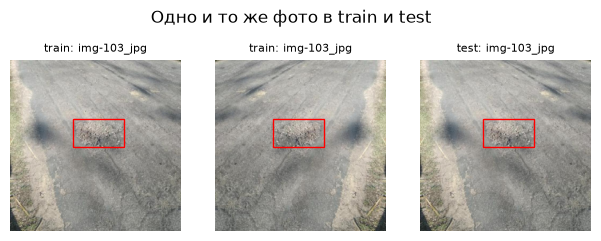

In [4]:
def show(rows, title):
    fig, axes = plt.subplots(1, len(rows), figsize=(2.5 * len(rows), 2.8))
    for ax, row in zip(axes, rows.itertuples()):
        image = plt.imread(row.file)
        ax.imshow(image)
        for b in boxes[boxes['file'] == row.file].itertuples():
            w, h = b.w * image.shape[1], b.h * image.shape[0]
            ax.add_patch(plt.Rectangle((b.xc * image.shape[1] - w / 2, b.yc * image.shape[0] - h / 2), w, h,
                                       fill=False, color='red'))
        ax.set_title(f'{row.split}: {row.name[:14]}', fontsize=8)
        ax.axis('off')
    fig.suptitle(title)
    plt.show()


test = images[images['split'] == 'test']
leak = test['photo'].isin(images[images['split'] == 'train']['photo'])
print('Файлов:', len(images), ', разных фото:', images['photo'].nunique(), ', разных имён:', images['name'].nunique())
print('Имён, под которыми лежат разные фото:', (images.groupby('name')['photo'].nunique() > 1).sum())
print(f'Картинок test, которые есть в train: {leak.sum()} из {len(test)} ({leak.mean():.0%})')
show(images[images['photo'] == test[leak]['photo'].iloc[0]], 'Одно и то же фото в train и test')

## Ямы на кадре

Дальше берём по одной копии каждого фото.

Ям на фото: медиана 2.0 , максимум 45
Ям меньше 1% кадра: 41%


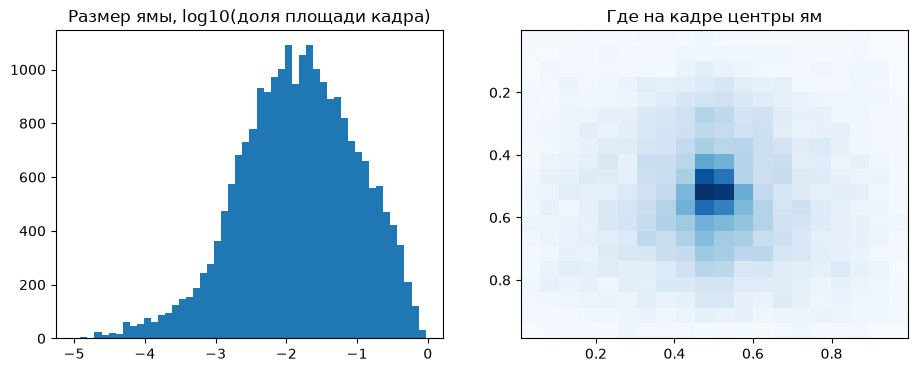

In [5]:
first_copy = images.drop_duplicates('photo')
b = boxes[boxes['file'].isin(first_copy['file'])]
area = b['w'] * b['h']
per_photo = b.groupby('file').size()
print('Ям на фото: медиана', per_photo.median(), ', максимум', per_photo.max())
print(f'Ям меньше 1% кадра: {(area < 0.01).mean():.0%}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log10(area), bins=50)
axes[0].set_title('Размер ямы, log10(доля площади кадра)')
axes[1].hist2d(b['xc'], b['yc'], bins=20, cmap='Blues')
axes[1].invert_yaxis()
axes[1].set_title('Где на кадре центры ям')
plt.show()

## Качество фото

Все фото растянуты до 640×640, поэтому маленькие исходники стали мутными.

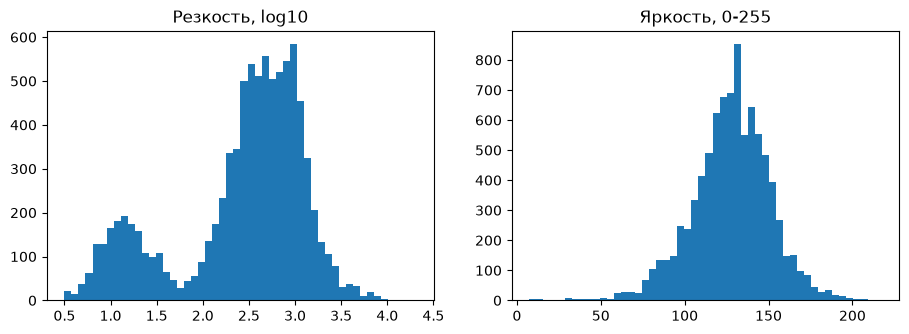

Очень мутных (резкость < 40): 18.2%
Очень тёмных (яркость < 35): 0.2%


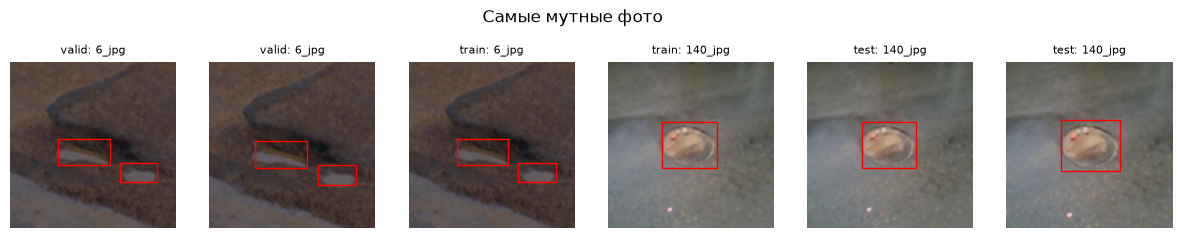

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(np.log10(first_copy['sharpness']), bins=50)
axes[0].set_title('Резкость, log10')
axes[1].hist(first_copy['brightness'], bins=50)
axes[1].set_title('Яркость, 0-255')
plt.show()

print(f"Очень мутных (резкость < 40): {(first_copy['sharpness'] < 40).mean():.1%}")
print(f"Очень тёмных (яркость < 35): {(first_copy['brightness'] < 35).mean():.1%}")
show(first_copy.nsmallest(6, 'sharpness'), 'Самые мутные фото')

## Итог


- 13 767 файлов, но разных фото около 6 500: Roboflow сохранил каждое фото в нескольких копиях, часть отражена.
- Половина картинок test (458 из 891) есть и в train, поэтому оценка на этих сплитах будет завышена.
- Под 533 именами лежат разные фото: датасет собран из многих наборов, имя файла не равно фото.
- Разметка: 33 899 рамок и 1 920 полигонов, класс в data.yaml называется 0.
- Около 10% фото очень мутные, ночных кадров почти нет, 47% ям меньше 1% кадра.
- При ручном сборе нужны чёткие фото, ночные и пасмурные кадры, ямы на разном расстоянии.